# Per-maze Session Chain

Trains one model per maze session by session: every usable session of the maze, all mice, in calendar order. Each session fine-tunes the model carried from the previous one on its first 60%, calibrates on the next 30% and is tested on its last 10%; the first sessions are a warm-up that is never tested. Writes one bundle per seed to `analyses/artifacts/<Paradigm>/ALL_MICE/seed_<SEED>/`, which `cross_maze.ipynb` reads. The compute lives in `src/chain/`; each cell is thin orchestration. Driven per maze and seed by `analyses/run_mazes.py` (`make maze`).

The parameters cell below is the run's source of truth: every value in it is passed explicitly and recorded in `metrics.json`. The model hyperparameters that are frozen for the study (learning rates, loss weights, model sizes, sigma's loss) stay in `src/`; they are printed below and recorded in `metrics.json` too.

0. Setup: Papermill Parameters And Imports
1. Data: Cohort, Windows, And The Chain
2. The Chain
3. Results: Methods And Sessions
4. Training Curves
5. Save The Bundle

## 0. Setup: Papermill Parameters And Imports

In [1]:
# papermill parameters: run_mazes.py overrides TARGET_PARADIGM, SEED, ARTIFACT_DIR,
# EXCLUDE_SESSIONS and, for smoke runs, the training budgets and SWEEP_TARGETS.

# --- cohort and output ---
# the maze: "More_Water", "Y_Maze" or "Nested_All"
TARGET_PARADIGM = "More_Water"
# restrict to these mouse ids (None = every usable mouse), or hold some out
TARGET_MICE = None
EXCLUDE_MICE = []
# sessions discarded before loading (recording quality), set per maze in run_mazes.py
EXCLUDE_SESSIONS = []
COHORT_LABEL = "ALL_MICE"
# "" derives analyses/artifacts/<Paradigm>/ALL_MICE/seed_<SEED>/
ARTIFACT_DIR = ""
# seed of every trained stage; run_mazes.py sweeps it
SEED = 42

# --- windows and labels ---
# a window's region: the most common bin label ("mode") or its last bin ("last")
LABEL_REDUCE = "mode"
# drop windows that straddle a trial boundary
DROP_STRADDLE_WINDOWS = True
# Linear maze: a trial keeps its water position only if this share of its bins agree
LINEAR_WATER_MIN_SHARE = 0.8

# --- the chain and its split ---
# leading sessions trained and calibrated but never tested, and their train share
WARMUP_SESSIONS = 3
WARMUP_TRAIN_FRAC = 0.70
# every later session: chronological train / calibration / test blocks
TRAIN_FRAC, CAL_FRAC, TEST_FRAC = 0.60, 0.30, 0.10
# a session needs this many calibration and test windows
MIN_CAL_WINDOWS = 50
MIN_TEST_WINDOWS = 20

# --- conformal calibration ---
# miscoverage: the coverage target is 1 - ALPHA
ALPHA = 0.10
# a region with too few calibration windows pools with the last BORROW_SESSIONS sessions'
# calibration blocks; SENSITIVITY_BORROW are also evaluated, as a sensitivity analysis
BORROW_SESSIONS = 3
SENSITIVITY_BORROW = [1, 5]
# coverage targets of the sweep (each but 1 - ALPHA retrains sigma); must include 1 - ALPHA
SWEEP_TARGETS = [round(0.05 * k, 2) for k in range(1, 20)]
# the fresh-model-per-session baseline (standard split conformal)
RUN_BASELINE = True

# --- training objective ---
# weight the encoder's and decoder's region losses by inverse region frequency (False: every
# window counts equally, so training optimizes raw accuracy, the reported metric)
CLASS_WEIGHTS = False

# --- training budgets per session ---
# Step 1 and Step 2: epoch cap and early-stopping patience
STEP_EPOCHS = 200
EARLY_STOP_PATIENCE = 20
# sigma: epoch cap and early-stopping patience
MLP_EPOCHS = 300
MLP_EARLY_STOP_PATIENCE = 30
# Step 1's KL warm-up, run only when a model is trained from scratch
KL_WARMUP_EPOCHS = 10

In [2]:
# Parameters
TARGET_PARADIGM = "More_Water"
ARTIFACT_DIR = "analyses/artifacts/More_Water/ALL_MICE/seed_42"
SEED = 42
EXCLUDE_SESSIONS = [
    "M46_250512",
    "M46_250424",
    "M25_241004",
    "M27_240920",
    "M19_241023",
    "M19_240922",
    "M21_241018",
    "M19_241018",
    "M21_241005",
]

In [3]:
# Setup: imports, seeds, device, output paths
import json
import sys
import time
from collections import Counter
from dataclasses import asdict
from pathlib import Path

# run from the repo root so `from src.X import ...` resolves whichever directory
_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists()),
    Path.cwd(),
)
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import torch

from src.chain.order import prepare_chain
from src.chain.runner import ChainConfig, run_chain
from src.chain.stages import TrainBudget
from src.db.client import get_database
from src.models import config as model_config
from src.utils import production_config
from src.utils.artifacts import (
    build_chain_bundle,
    jsonify,
    paradigm_slug,
    sigma_nets_payload,
)
from src.utils.cohort import apply_session_exclusions, discover_cohort
from src.utils.pipeline_prep import (
    apply_window_region_labels,
    assemble_session_data,
    assert_chronological_disjoint,
    force_session_specific,
    gate_sessions_conformal,
)

assert np.isclose(TRAIN_FRAC + CAL_FRAC + TEST_FRAC, 1.0), "the split must sum to 1"
assert any(np.isclose(t, 1 - ALPHA) for t in SWEEP_TARGETS), "the sweep needs 1 - ALPHA"

torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACT_DIR = (
    Path(ARTIFACT_DIR)
    if ARTIFACT_DIR
    else _ROOT
    / "analyses"
    / "artifacts"
    / paradigm_slug(TARGET_PARADIGM)
    / COHORT_LABEL
    / f"seed_{SEED}"
)
CHECKPOINT = ARTIFACT_DIR / "checkpoint.pt"
print(f"PyTorch {torch.__version__}  |  device {DEVICE}  |  seed {SEED}")
print(f"bundle -> {ARTIFACT_DIR}")

PyTorch 2.12.0+cu130  |  device cpu  |  seed 42
bundle -> analyses/artifacts/More_Water/ALL_MICE/seed_42


The hyperparameters frozen for the study: not exposed as parameters, printed here and recorded in `metrics.json` with the parameters above.

In [4]:
FROZEN = {
    "step1_learning_rate": model_config.STEP1_LEARNING_RATE,
    "step2_learning_rate": model_config.STEP2_LEARNING_RATE,
    "batch_size": model_config.BATCH_SIZE,
    "latent_dim": model_config.LATENT_DIM,
    "hidden_dim": model_config.HIDDEN_DIM,
    "step2_seq_len": model_config.STEP2_SEQ_LEN,
    "early_stop_min_delta": model_config.MAIN_EARLY_STOP_MIN_DELTA,
    "step1_region_weight": production_config.STEP1_REGION_WEIGHT,
    "step1_kl_weight": production_config.STEP1_KL_WEIGHT,
    "step1_kl_free_bits": production_config.STEP1_KL_FREE_BITS,
    "step1_class_weight_power": production_config.STEP1_CLASS_WEIGHT_POWER,
    "step1_weight_decay": production_config.STEP1_WEIGHT_DECAY,
    "step2_contrastive_weight": production_config.STEP2_CONTRASTIVE_WEIGHT,
    "step2_dropout": production_config.STEP2_DROPOUT,
    "step2_class_weight_power": production_config.STEP2_CLASS_WEIGHT_POWER,
    "sigma_hidden": production_config.MLP_HIDDEN,
    "sigma_depth": production_config.MLP_DEPTH,
    "sigma_tau": production_config.MLP_TAU,
    "sigma_kappa": production_config.MLP_KAPPA,
    "sigma_size_weight": production_config.MLP_SIZE_WEIGHT,
    "sigma_split": production_config.MLP_CAL_SPLIT,
}
for k, v in FROZEN.items():
    print(f"  {k:<26} {v}")

  step1_learning_rate        0.001
  step2_learning_rate        0.0003
  batch_size                 256
  latent_dim                 16
  hidden_dim                 128
  step2_seq_len              5
  early_stop_min_delta       0.0001
  step1_region_weight        0.2
  step1_kl_weight            0.5
  step1_kl_free_bits         0.0
  step1_class_weight_power   1.0
  step1_weight_decay         0.01
  step2_contrastive_weight   2.0
  step2_dropout              0.1
  step2_class_weight_power   1.0
  sigma_hidden               32
  sigma_depth                2
  sigma_tau                  0.05
  sigma_kappa                20.0
  sigma_size_weight          1.0
  sigma_split                chronological


## 1. Data: Cohort, Windows, And The Chain

Discovers every usable mouse and session in `TARGET_PARADIGM` and pools them into one cohort.

In [5]:
# Cohort: every usable mouse in TARGET_PARADIGM, pooled into one group. A mouse
# with < 2 valid sessions in the paradigm is skipped.
db = get_database()
print(f"Connected: {db.name}\n")
cohort = discover_cohort(
    db,
    TARGET_PARADIGM,
    target_mice=TARGET_MICE,
    exclude_mice=EXCLUDE_MICE,
)
_PARADIGMS = cohort.paradigms
paradigm = cohort.label
n_classes = cohort.n_classes
group = cohort.group
_pool_pre_exclusion = set(group)
group = apply_session_exclusions(group, EXCLUDE_SESSIONS, log_fn=print)

# provenance for metrics.json so the manual curation is auditable from the saved bundle alone.
EXCLUDED_REQUESTED = list(EXCLUDE_SESSIONS)
EXCLUDED_APPLIED = sorted(_pool_pre_exclusion - set(group))
session_to_mouse = cohort.session_to_mouse
session_to_paradigm = cohort.session_to_paradigm
cohort_mice = cohort.cohort_mice
mouse_id_used = COHORT_LABEL

print(f"cohort {COHORT_LABEL}  paradigm={paradigm!r}  ({n_classes} regions)")
if len(_PARADIGMS) > 1:
    print(f"  pooled over {len(_PARADIGMS)} paradigm blocks: {_PARADIGMS}")
print(f"  {len(cohort_mice)} usable mice: {cohort_mice}")
print(f"  {len(group)} candidate sessions pooled across mice")
if cohort.skipped:
    print(
        f"  {len(cohort.skipped)} mice skipped (no >=2 valid sessions in {TARGET_PARADIGM!r}): "
        f"{[f'M{m}: {w}' for m, w in cohort.skipped]}"
    )

Connected: functional_atlas



  EXCLUDE_SESSIONS: dropped 9 session(s) before assembly: ['M19_240922', 'M19_241018', 'M19_241023', 'M21_241005', 'M21_241018', 'M25_241004', 'M27_240920', 'M46_250424', 'M46_250512']
cohort ALL_MICE  paradigm='More_Water'  (8 regions)
  13 usable mice: [19, 21, 23, 25, 27, 40, 41, 46, 47, 48, 49, 50, 52]
  137 candidate sessions pooled across mice


Bins spikes into 1 s windows, labels each window's maze region (Linear: eighths of the run to the trial's water), splits every session chronologically into train, calibration and test blocks over task windows, and drops sessions too small to calibrate or test.

In [6]:
# Assemble: bin spikes -> window -> region labels -> the chronological split
session_data, valid_sessions, session_configs, _, n_shared = assemble_session_data(
    db,
    group,
    paradigm,
    train_frac=TRAIN_FRAC,
    val_frac=CAL_FRAC,
    test_frac=TEST_FRAC,
    water_min_share=LINEAR_WATER_MIN_SHARE,
)
if n_shared > 0:
    force_session_specific(session_configs)
apply_window_region_labels(
    session_data,
    valid_sessions,
    paradigm,
    reduce=LABEL_REDUCE,
    drop_straddle=DROP_STRADDLE_WINDOWS,
    log_fn=print,
)
_unused = [s for s in group if s not in valid_sessions]
if _unused:
    print(f"{len(_unused)} session(s) rejected by assembly: {', '.join(_unused)}")
_dropped = gate_sessions_conformal(
    session_data, valid_sessions, MIN_CAL_WINDOWS, MIN_TEST_WINDOWS
)
for s, nv, nt in _dropped:
    print(f"gated out {s}: calibration {nv}, test {nt}")
assert_chronological_disjoint(session_data, valid_sessions)
if len(valid_sessions) <= WARMUP_SESSIONS:
    raise RuntimeError(
        f"{paradigm}: {len(valid_sessions)} sessions, nothing to test after the warm-up"
    )
print(f"{len(valid_sessions)} usable sessions")

33 session(s) rejected by assembly: M19_241005, M27_241004, M40_250126, M40_250207, M40_250223, M40_250303, M40_250321, M40_250323, M46_250330, M46_250414, M46_250418, M46_250420, M46_250430, M47_250223, M47_250307, M47_250309, M48_250222, M48_250224, M48_250228, M48_250302, M48_250317, M48_250322, M48_250420, M48_250424, M48_250426, M48_250504, M49_250419, M49_250425, M49_250509, M49_250512, M50_250411, M50_250413, M50_250419
gated out M50_250428: calibration 17, test 5
gated out M50_250501: calibration 29, test 7
102 usable sessions


Orders the sessions into the chain (calendar order, all mice), re-splits the warm-up sessions into train and calibration blocks, and z-scores every session's neurons on its own training block.

In [7]:
# The chain: calendar order, warm-up re-split, per-session normalization
chain = prepare_chain(session_data, valid_sessions, WARMUP_SESSIONS, WARMUP_TRAIN_FRAC)
mouse = {s: str(session_to_mouse[s]) for s in chain}
print(
    f"chain: {len(chain)} sessions from {len(set(mouse.values()))} mice  |  "
    f"warm-up {chain[:WARMUP_SESSIONS]}  |  {len(chain) - WARMUP_SESSIONS} tested"
)
for m, n in sorted(Counter(mouse.values()).items()):
    print(f"  M{m}: {n} sessions")

chain: 102 sessions from 13 mice  |  warm-up ['M19_240914', 'M23_240914', 'M25_240916']  |  99 tested
  M19: 6 sessions
  M21: 7 sessions
  M23: 3 sessions
  M25: 7 sessions
  M27: 5 sessions
  M40: 15 sessions
  M41: 4 sessions
  M46: 10 sessions
  M47: 9 sessions
  M48: 11 sessions
  M49: 8 sessions
  M50: 12 sessions
  M52: 5 sessions


Region distribution over every task window of the chain, against chance.

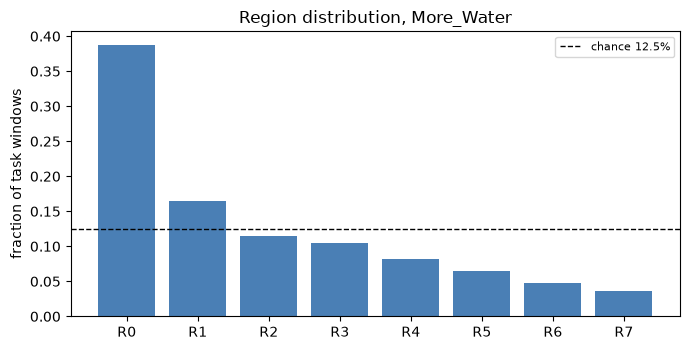

In [8]:
_counts = np.zeros(n_classes)
for s in chain:
    d = session_data[s]
    _task = np.concatenate([d["train_idx"], d["val_idx"], d["test_idx"]])
    _counts += np.bincount(d["regions"][_task], minlength=n_classes)
_share = _counts / _counts.sum()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(n_classes), _share, color="#4a7fb5")
ax.axhline(1 / n_classes, ls="--", color="k", lw=1, label=f"chance {1 / n_classes:.1%}")
ax.set_xticks(range(n_classes))
ax.set_xticklabels([f"R{r}" for r in range(n_classes)])
ax.set_ylabel("fraction of task windows")
ax.set_title(f"Region distribution, {paradigm}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. The Chain

Runs the chain: each session fine-tunes the encoder, decoder and sigma carried from the previous session, and every session after the warm-up is evaluated: the method, the pool-rule sensitivity, the sigma = 1 ablation, the coverage sweep and the fresh-model baseline. Every session's training curves are logged. A checkpoint after every session lets an interrupted run resume where it stopped.

In [9]:
cfg = ChainConfig(
    seed=SEED,
    device=DEVICE,
    warmup=WARMUP_SESSIONS,
    alpha=ALPHA,
    rule=f"B{BORROW_SESSIONS}",
    sensitivity=tuple(f"B{m}" for m in SENSITIVITY_BORROW),
    sweep_targets=tuple(float(t) for t in SWEEP_TARGETS),
    baseline=RUN_BASELINE,
    class_weights=CLASS_WEIGHTS,
    budget=TrainBudget(
        epochs=STEP_EPOCHS,
        patience=EARLY_STOP_PATIENCE,
        mlp_epochs=MLP_EPOCHS,
        mlp_patience=MLP_EARLY_STOP_PATIENCE,
        kl_warmup_epochs=KL_WARMUP_EPOCHS,
    ),
)
training_log: list = []
_t0 = time.time()
rows = run_chain(
    session_data,
    chain,
    session_configs,
    n_classes,
    mouse,
    cfg,
    checkpoint=CHECKPOINT,
    training_log=training_log,
)
print(f"chain done in {(time.time() - _t0) / 60:.1f} min, {len(rows)} sessions tested")

.venv/lib/python3.12/site-packages/torch/nn/modules/linear.py:124: UserWarning: Initializing zero-element tensors is a no-op
  init.kaiming_uniform_(self.weight, a=math.sqrt(5))


[1/102] M19_240914  warm-up


[2/102] M23_240914  warm-up


[3/102] M25_240916  warm-up


.venv/lib/python3.12/site-packages/torch/nn/modules/linear.py:124: UserWarning: Initializing zero-element tensors is a no-op
  init.kaiming_uniform_(self.weight, a=math.sqrt(5))


...

[99/102] M52_250615  acc 0.39  cov 0.93  |C|/K 0.96


[100/102] M52_250616  acc 0.26  cov 0.98  |C|/K 0.98


[101/102] M52_250618  acc 0.12  cov 0.99  |C|/K 0.98


[102/102] M52_250619  acc 0.75  cov 0.92  |C|/K 0.88


chain done in 937.9 min, 99 sessions tested


## 3. Results: Methods And Sessions

Every method pooled over the test windows of all tested sessions: the deployed chain, the sigma = 1 ablation, the fresh-model baseline and the pool-rule sensitivity. `|gap|` is the mean over sessions of each session's distance from the target; `below` counts sessions under it; `global` is the share of test windows whose region fell back to the session's global threshold.

In [10]:
metrics, arrays = build_chain_bundle(
    rows,
    chain=chain,
    n_warmup=WARMUP_SESSIONS,
    session_data=session_data,
    n_classes=n_classes,
    paradigm=paradigm,
    seed=SEED,
    alpha=ALPHA,
    rule=cfg.rule,
    config={
        **asdict(cfg),
        "data": {
            "label_reduce": LABEL_REDUCE,
            "drop_straddle_windows": DROP_STRADDLE_WINDOWS,
            "linear_water_min_share": LINEAR_WATER_MIN_SHARE,
            "split": [TRAIN_FRAC, CAL_FRAC, TEST_FRAC],
            "warmup_train_frac": WARMUP_TRAIN_FRAC,
            "min_cal_windows": MIN_CAL_WINDOWS,
            "min_test_windows": MIN_TEST_WINDOWS,
        },
        "frozen": FROZEN,
    },
    training=training_log,
)
metrics["excluded_sessions"] = {
    "requested": EXCLUDED_REQUESTED,
    "applied": EXCLUDED_APPLIED,
}
TARGET = 1 - ALPHA
MAIN = f"chain_{cfg.rule}"
_all = metrics["conformal"]["methods"]["all"]
METHODS = [MAIN, "chain_sigma1", "fresh", *(f"chain_{r}" for r in cfg.sensitivity)]
METHODS = [m for m in METHODS if m in _all]
print(
    f"  {'method':<14} {'cov':>6} {'|C|/K':>6} {'acc':>6} {'|gap|':>6} {'below':>6} {'global':>7}"
)
for name in METHODS:
    m = _all[name]
    print(
        f"  {name:<14} {m['coverage']:>6.3f} {m['size_over_k']:>6.3f} {m['accuracy']:>6.3f} "
        f"{m['mean_abs_gap']:>6.3f} {m['sessions_below']:>6d} {m['share_global']:>7.2f}"
    )

  method            cov  |C|/K    acc  |gap|  below  global
  chain_B3        0.865  0.827  0.230  0.070     57    0.02
  chain_sigma1    0.830  0.774  0.230  0.097     66    0.02
  fresh           0.766  0.679  0.230  0.172     72    1.00
  chain_B1        0.850  0.801  0.230  0.083     58    0.07
  chain_B5        0.871  0.836  0.230  0.066     54    0.00


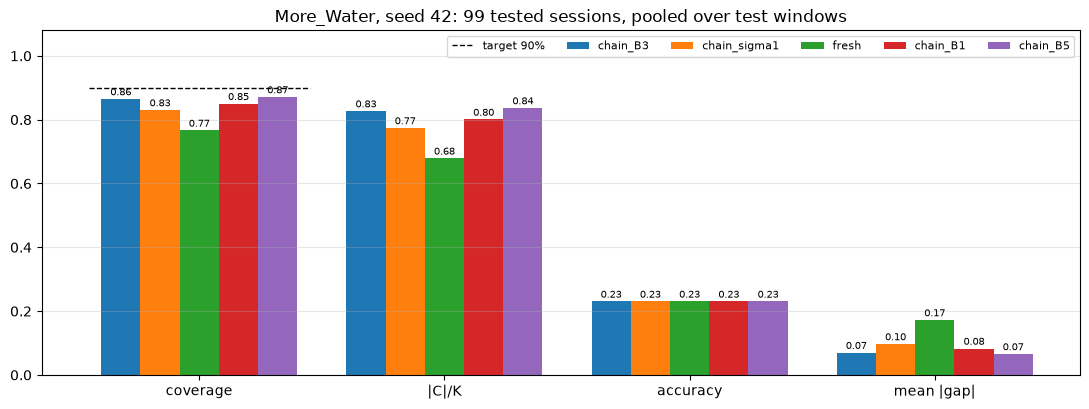

In [11]:
# Methods side by side: one group of bars per metric, one bar per method
_metric_keys = [
    ("coverage", "coverage"),
    ("size_over_k", "|C|/K"),
    ("accuracy", "accuracy"),
    ("mean_abs_gap", "mean |gap|"),
]
_width = 0.8 / len(METHODS)
_colors = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(11, 4.2))
for j, name in enumerate(METHODS):
    _vals = [_all[name][k] for k, _ in _metric_keys]
    _pos = np.arange(len(_metric_keys)) + (j - (len(METHODS) - 1) / 2) * _width
    _bars = ax.bar(_pos, _vals, _width, label=name, color=_colors(j))
    ax.bar_label(_bars, fmt="%.2f", fontsize=7, padding=1)
ax.hlines(
    TARGET, -0.45, 0.45, colors="k", linestyles="--", lw=1, label=f"target {TARGET:.0%}"
)
ax.set_xticks(range(len(_metric_keys)))
ax.set_xticklabels([label for _, label in _metric_keys])
ax.set_ylim(0, 1.08)
ax.set_title(
    f"{paradigm}, seed {SEED}: {len(rows)} tested sessions, pooled over test windows"
)
ax.legend(fontsize=8, ncol=len(METHODS) + 1, loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The deployed method per tested session, in chain order: coverage, |C|/K and accuracy. Grey lines and the mouse labels mark each mouse's first session.

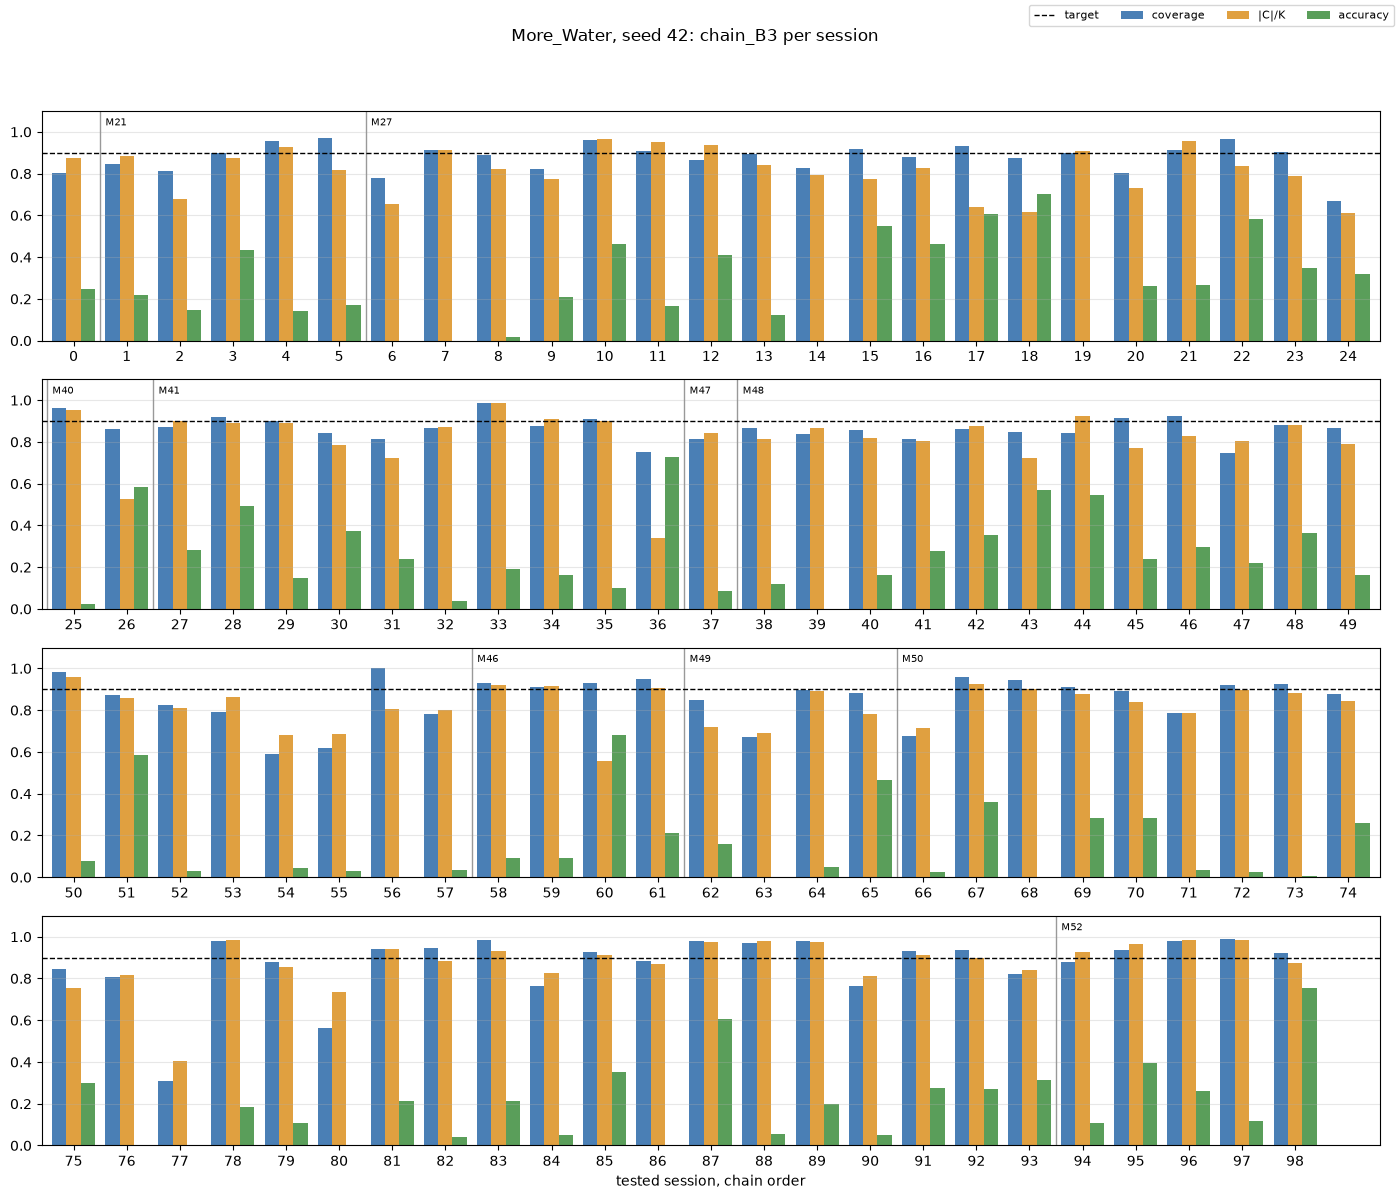

In [12]:
PER_ROW = 25
_series = [
    ("coverage", [r["methods"][MAIN]["covered"].mean() for r in rows], "#4a7fb5"),
    ("|C|/K", [r["methods"][MAIN]["size_over_k"].mean() for r in rows], "#e0a040"),
    ("accuracy", [1 - r["methods"][MAIN]["error"].mean() for r in rows], "#5a9e5a"),
]
_n_rows = -(-len(rows) // PER_ROW)
fig, axes = plt.subplots(_n_rows, 1, figsize=(14, 3.0 * _n_rows), squeeze=False)
for k, ax in enumerate(axes[:, 0]):
    _idx = np.arange(k * PER_ROW, min((k + 1) * PER_ROW, len(rows)))
    for j, (label, vals, color) in enumerate(_series):
        ax.bar(
            _idx + (j - 1) * 0.27,
            [vals[i] for i in _idx],
            0.27,
            color=color,
            label=label if k == 0 else None,
        )
    for i in _idx:
        if rows[i]["first_of_mouse"]:
            ax.axvline(i - 0.5, color="0.6", lw=1)
            ax.text(i - 0.4, 1.02, f"M{rows[i]['mouse']}", fontsize=7, va="bottom")
    ax.axhline(TARGET, ls="--", color="k", lw=1, label="target" if k == 0 else None)
    ax.set_xlim(k * PER_ROW - 0.6, k * PER_ROW + min(PER_ROW, len(rows)) - 0.4)
    ax.set_xticks(_idx)
    ax.set_ylim(0, 1.1)
    ax.grid(axis="y", alpha=0.3)
axes[-1, 0].set_xlabel("tested session, chain order")
fig.suptitle(f"{paradigm}, seed {SEED}: {MAIN} per session")
fig.legend(fontsize=8, ncol=4, loc="upper right")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 4. Training Curves

The held-out loss each trained stage early-stopped on, for every session of the chain (Step 1: its validation loss; Step 2: its region loss; sigma: its conformal loss on the late part of the training block). Each curve is drawn relative to the epoch whose weights were restored (the dot, at 0; without a restore, relative to the curve's minimum), so sessions with different loss levels share one axis; the vertical axis is linear near 0 and logarithmic beyond. Color is the session's chain position. The first session trains from scratch; every later one fine-tunes.

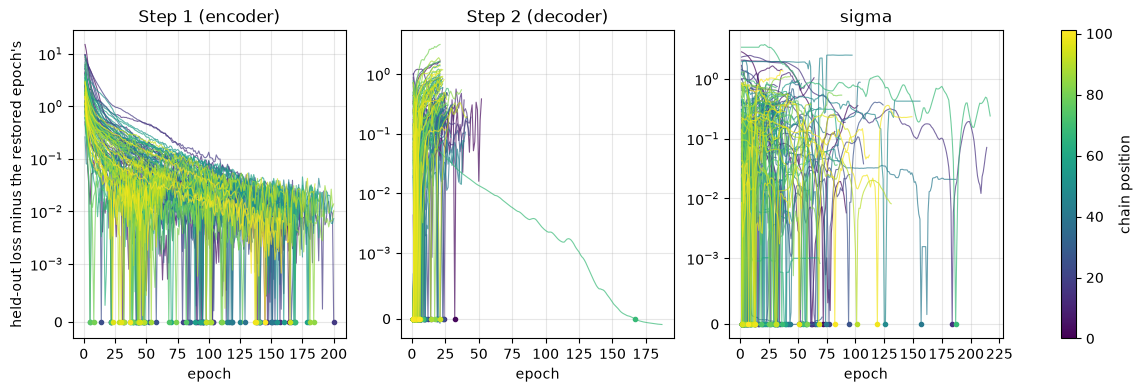

In [13]:
STAGES = [
    ("step1", "Step 1 (encoder)"),
    ("step2", "Step 2 (decoder)"),
    ("sigma", "sigma"),
]
_cmap = plt.get_cmap("viridis")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (stage, title) in zip(axes, STAGES, strict=True):
    for i, e in enumerate(training_log):
        c = e[stage]
        if not c or not c["val_loss"]:
            continue
        y = np.array([np.nan if v is None else v for v in c["val_loss"]], dtype=float)
        if np.isnan(y).all():
            continue
        best = c["best_epoch"]
        y = y - (y[best - 1] if best is not None else np.nanmin(y))
        color = _cmap(i / max(len(training_log) - 1, 1))
        ax.plot(np.arange(1, len(y) + 1), y, color=color, lw=0.8, alpha=0.7)
        if best is not None:
            ax.plot(best, 0, "o", color=color, ms=3)
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.set_yscale("symlog", linthresh=1e-3)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("held-out loss minus the restored epoch's")
fig.colorbar(
    plt.cm.ScalarMappable(cmap=_cmap, norm=plt.Normalize(0, len(training_log) - 1)),
    ax=axes,
    label="chain position",
)
plt.show()

Epochs run and the restored epoch per session and stage. A restored epoch close to the epochs run means the stage was still improving when it stopped; hitting the epoch cap (dashed) means the budget, not early stopping, ended it. Shaded: the warm-up sessions.

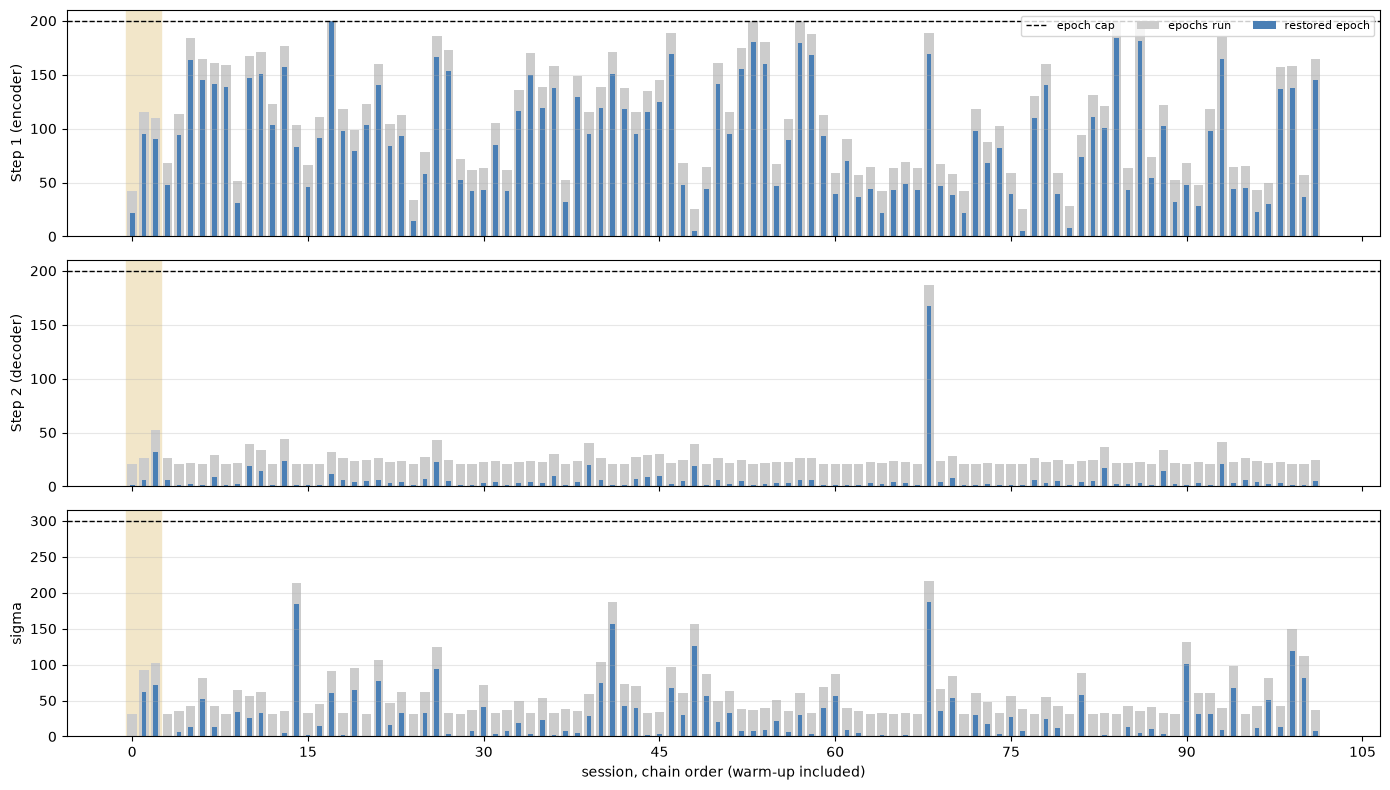

In [14]:
_caps = {"step1": STEP_EPOCHS, "step2": STEP_EPOCHS, "sigma": MLP_EPOCHS}
_x = np.arange(len(training_log))
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, (stage, title) in zip(axes, STAGES, strict=True):
    _run = [e[stage]["epochs"] if e[stage] else 0 for e in training_log]
    _best = [(e[stage] or {}).get("best_epoch") or 0 for e in training_log]
    ax.bar(_x, _run, 0.8, color="0.8", label="epochs run")
    ax.bar(_x, _best, 0.4, color="#4a7fb5", label="restored epoch")
    ax.axhline(_caps[stage], ls="--", color="k", lw=1, label="epoch cap")
    ax.axvspan(-0.5, WARMUP_SESSIONS - 0.5, color="#f2e6c9", zorder=0)
    ax.set_ylabel(title)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8, ncol=3, loc="upper right")
axes[-1].set_xlabel("session, chain order (warm-up included)")
axes[-1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

## 5. Save The Bundle

Writes `sigma_nets.pt`, `metrics.json` and, last, `arrays.npz` (its presence marks the bundle complete for `run_mazes.py`), then removes the chain checkpoint. `arrays.npz` keeps the test windows' probabilities, sigma, positions and sweep results, every calibration score (the own block and the re-scored past blocks), so any calibration rule can be recomputed offline, and the windows each session's sigma was trained and calibrated on, so another sigma can be trained offline on the same decoder outputs.

In [15]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
torch.save(
    sigma_nets_payload(rows, production_config.MLP_HIDDEN, production_config.MLP_DEPTH),
    ARTIFACT_DIR / "sigma_nets.pt",
)
(ARTIFACT_DIR / "metrics.json").write_text(json.dumps(jsonify(metrics), indent=2))
np.savez_compressed(ARTIFACT_DIR / "arrays.npz", **arrays)
CHECKPOINT.unlink(missing_ok=True)
print(f"saved -> {ARTIFACT_DIR}: sigma_nets.pt, metrics.json, arrays.npz")

saved -> analyses/artifacts/More_Water/ALL_MICE/seed_42: sigma_nets.pt, metrics.json, arrays.npz
